# 2. Uncertainty calibration (split-conformal prediction)

**Component 3, Electricity Demand Forecasting with Scenario Analysis** | Dewmini D.M.D.P (IT22630216)

**The problem.** A forecast of "2,012 kW" is never exactly right. Planners need to know *how wrong it could be*.

**The method: split-conformal prediction.**
1. Take the held-out **test** rows (never used for training) and split them into two halves.
2. On the **calibration half**, measure the model's errors and find the error size that covers 90% of them. That is the interval half-width.
3. On the **evaluation half**, check that the interval really contains about 90% of actual values. This is the proof that the ranges can be trusted.

The same error distribution is also used by the Grid Decision Lab to turn a forecast into an **overload probability**.

**Data:** `notebooks/load_forecasting_dataset_corrected.csv` (189,888 fifteen-minute records, 2020 to 2025, 13 input features).

**Outputs written** (same as `scripts/calibrate.py`): `backend/saved_models/conformal.json` and `performance.json`.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent
MODELS = ROOT / 'backend' / 'saved_models'
plt.rcParams['figure.dpi'] = 100

meta = json.load(open(MODELS / 'model_metadata.json'))
FEATURES, TARGET = meta['feature_names'], meta['target_column']
model = joblib.load(MODELS / 'forecast_model.pkl')
df = pd.read_csv(ROOT / 'notebooks' / 'load_forecasting_dataset_corrected.csv')
print('Loaded model:', meta['model_type'])

Loaded model: GradientBoostingRegressor


## Step 1: Recreate the held-out test set and split it in two
We use the **same split** as notebook 1 (`test_size=0.2, random_state=42`), so these rows were never seen during training.
Then we cut the test rows in half: one half to calibrate, one half to check.

In [2]:
_, X_test, _, y_test = train_test_split(df[FEATURES], df[TARGET], test_size=0.2, random_state=42)   # same split as notebook 1
X_cal, X_eval, y_cal, y_eval = train_test_split(X_test, y_test, test_size=0.5, random_state=7)
print(f'Calibration rows: {len(X_cal):,} | Evaluation rows: {len(X_eval):,}')

Calibration rows: 18,989 | Evaluation rows: 18,989


## Step 2: Measure the errors (residuals)
Residual = actual - predicted. Their spread tells us how uncertain a forecast is.

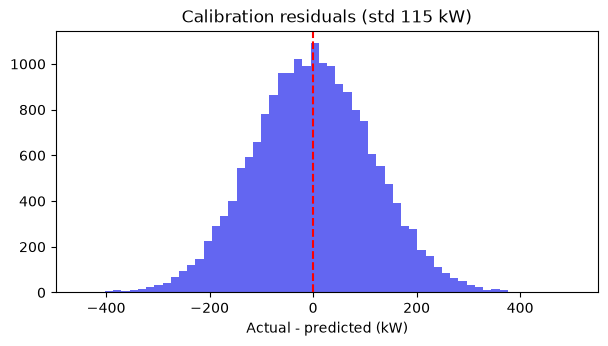

In [3]:
res_cal = (y_cal - model.predict(X_cal)).to_numpy()
pred_eval = model.predict(X_eval)
res_eval = y_eval.to_numpy() - pred_eval

plt.figure(figsize=(7, 3.4))
plt.hist(res_cal, bins=60, color='#6366f1'); plt.axvline(0, color='r', ls='--')
plt.title(f'Calibration residuals (std {res_cal.std():.0f} kW)'); plt.xlabel('Actual - predicted (kW)'); plt.show()

## Step 3: Build and check the intervals
For a confidence level `c`, the half-width `q` is the `c`-quantile of the absolute errors (with a small finite-sample correction,
`ceil((n+1)c)/n`). A forecast `p` then gets the range `p - q` to `p + q`.

**The check:** the fraction of *evaluation* rows whose actual value falls inside the range should be close to `c`.

In [4]:
n = len(res_cal)
conformal = {'n_calibration': n, 'n_evaluation': len(y_eval), 'levels': {}}
for conf in (0.8, 0.9, 0.95):
    q = float(np.quantile(np.abs(res_cal), min(1.0, np.ceil((n + 1) * conf) / n)))   # finite-sample corrected quantile
    coverage = float(np.mean(np.abs(res_eval) <= q))                                   # honest check on unseen rows
    conformal['levels'][str(conf)] = {'half_width_kw': q, 'empirical_coverage': coverage}

pd.DataFrame(conformal['levels']).T.rename(columns={'half_width_kw': 'half-width (kW)', 'empirical_coverage': 'actually contained'}).round(3)

,half-width (kW),actually contained
0.8,146.745,0.799
0.9,188.841,0.898
0.95,225.030,0.950


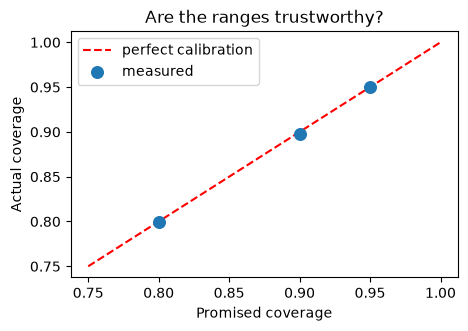

In [5]:
# Visual: promised vs achieved coverage
levels = list(conformal['levels'])
plt.figure(figsize=(5, 3.2))
plt.plot([0.75, 1], [0.75, 1], 'r--', label='perfect calibration')
plt.scatter([float(l) for l in levels], [conformal['levels'][l]['empirical_coverage'] for l in levels], s=70, zorder=3, label='measured')
plt.xlabel('Promised coverage'); plt.ylabel('Actual coverage'); plt.legend(); plt.title('Are the ranges trustworthy?'); plt.show()

## Step 4: One day with its uncertainty band
What a user sees in the dashboard: the forecast line with a 90% range around it.

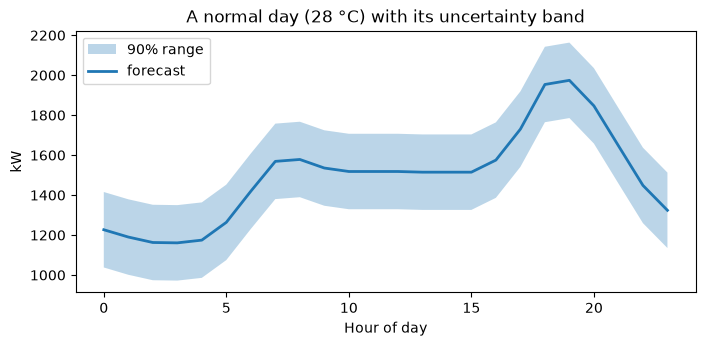

In [6]:
q90 = conformal['levels']['0.9']['half_width_kw']
sample = pd.DataFrame([{**dict(zip(FEATURES, [28, 80, 2, 5, 250, 1000, 500, 25, 2, h, 6, 0, 0]))} for h in range(24)])[FEATURES]
curve = model.predict(sample)
plt.figure(figsize=(8, 3.4))
plt.fill_between(range(24), curve - q90, curve + q90, alpha=0.3, label='90% range')
plt.plot(range(24), curve, lw=2, label='forecast')
plt.xlabel('Hour of day'); plt.ylabel('kW'); plt.title('A normal day (28 °C) with its uncertainty band'); plt.legend(); plt.show()

## Step 5: Save the risk lookup
The Grid Decision Lab needs the **whole error distribution**, not just three widths, so it can answer "how often is the error larger than
the spare capacity?". We store 1,001 quantiles of the calibration residuals (a compact summary of the distribution).

In [7]:
quantiles = np.linspace(0, 1, 1001)
conformal['residual_quantiles'] = np.quantile(res_cal, quantiles).round(2).tolist()
json.dump(conformal, open(MODELS / 'conformal.json', 'w'))
print('Saved conformal.json')

# Example of how the lookup is used: chance that the error exceeds 150 kW of spare room
rq = np.array(conformal['residual_quantiles'])
print('P(error > 150 kW) =', round(1 - np.searchsorted(rq, 150, side='right') / len(rq), 4))

Saved conformal.json
P(error > 150 kW) = 0.0969


## Step 6: Save the performance summary
`GET /api/performance` serves this file to the Performance tab (metrics, model comparison, and diagnostic data).

In [8]:
rng = np.random.default_rng(1)
idx = rng.choice(len(y_eval), 500, replace=False)
hist, edges = np.histogram(res_eval, bins=30)
performance = {
    'metrics': meta['model_performance'], 'comparison': meta['model_comparison'], 'importances': meta['feature_importances'],
    'scatter': [{'actual': float(y_eval.iloc[i]), 'predicted': float(pred_eval[i])} for i in idx],
    'error_hist': [{'from': float(edges[i]), 'to': float(edges[i + 1]), 'count': int(hist[i])} for i in range(len(hist))],
    'error_mean': float(res_eval.mean()), 'error_std': float(res_eval.std()),
    'coverage': conformal['levels'],
    'by_hour': [{'hour': int(h), 'mae': float(np.abs(res_eval[(X_eval['Hour of Day'] == h).to_numpy()]).mean())} for h in range(24)],
    'evaluation_rows': len(y_eval),
}
json.dump(performance, open(MODELS / 'performance.json', 'w'))
print('Saved performance.json | evaluation R2 =', round(r2_score(y_eval, pred_eval), 4), '| MAE =', round(mean_absolute_error(y_eval, pred_eval), 1))

Saved performance.json | evaluation R2 = 0.8243 | MAE = 91.7


## Summary
* The 90% range is about **±187 kW** and contained about **89.6%** of unseen actual values, so it is well calibrated.
* These ranges and the stored error distribution power the uncertainty band and the overload probabilities in the Grid Decision Lab.
* **Next:** `3_scenario_analysis.ipynb` uses the saved model for what-if scenarios.